In [3]:
import pandas as pd
import numpy as np
import os
os.makedirs("figures", exist_ok=True)

## Text Length Analysis

In [4]:
df = pd.read_csv("../scraped_data/scraped_data.csv")
df.shape

(150217, 9)

In [3]:
df.iloc[120,3]

'President Donald Trump ’s heated meeting with Ukraine’s leader has prompted Taiwan to start rethinking how it deals with the US, according to Taipei’s top defense official.\n\n“We have deeply recognized that one cannot discuss values without also addressing national interests,” Defense Minister Wellington Koo said at a media briefing on Monday, just before Trump ordered a pause to all military aid to Ukraine.'

In [5]:
#steps
#filter out rows where date is Nan
df_dated=df[~df["publish_date"].isna()]

df_dated=df_dated.dropna(subset=["text"],inplace=False).copy()
df_dated

,Unnamed: 0,sid,title,text,publish_date,authors,keywords,media_url,url
0,0,1934d046f2065ccf51bedd12962f5614ddb5714ae19f5a...,"Douglas Andrews, Thomas Gallatin, & Jordan Can...",Trump to give a non-State of the Union address...,2025-03-04 00:00:00,[],[],patriotpost.us,https://patriotpost.us/articles/115018-tuesday...
7,7,f5a41b15c7ed9fe08efe5be1fbd9645f679935db4b17a0...,Air Force picks remote Pacific atoll as site f...,"Johnston Island, as seen from a U.S. Coast Gua...",2025-03-04 00:00:00,[],[],stripes.com,https://www.stripes.com/theaters/asia_pacific/...
8,8,8370fc28c38e87162aa4fc46c056a830f832fa42d82239...,"Marines, Japanese forces prepare for amphibiou...",A member of Japan's Amphibious Rapid Deploymen...,2025-03-02 00:00:00,[],[],stripes.com,https://www.stripes.com/theaters/asia_pacific/...
9,9,a21fd8ef89d7ee56d3ebbc5a7defedf6c3a4905fa02dc7...,Transcript of President Donald Trump’s speech ...,WASHINGTON (AP) — A transcript of President Do...,2025-03-04 00:00:00,['Associated Press'],[],sandiegouniontribune.com,https://www.sandiegouniontribune.com/2025/03/0...
11,11,a263f9c800da39efa0a8d2724b541833248ca0e8d3ef79...,Trump Describes a Bold Trade Agenda for Americ...,President Trump laid out an ambitious plan on ...,2025-03-04 00:00:00,['John Carney'],[],breitbart.com,https://www.breitbart.com/economy/2025/03/04/t...
...,...,...,...,...,...,...,...,...,...
150185,150185,05fe8fdbed0b48936712ed11348c2f6183fe5ae325723a...,Pentagon: China's nuclear arsenal growing much...,1 of 7 | A new report says Beijing may have up...,2021-11-04 00:00:00,['Thomas Maresca'],[],upi.com,https://www.upi.com/Top_News/World-News/2021/1...
150196,150196,ed885a5cddda1ccd8bb9c5ebe71a551502cc5489e4c62e...,Blaze in Taiwan apartment building kills dozens,By Huizhong Wu | Associated Press\n\nKAOHSIUNG...,2021-10-14 00:00:00,['The Associated Press'],[],mercurynews.com,https://www.mercurynews.com/2021/10/14/blaze-i...
150197,150197,36fa755a4292728bd2dcb9d0b8e03a8167a6cc21e51b12...,U.S. and China Agree to Broaden Talks in Bid t...,"After the meeting, the Chinese ministry of com...",2023-08-28 00:00:00,"['Ana Swanson', 'Keith Bradsher', 'More About ...",[],nytimes.com,https://www.nytimes.com/2023/08/28/business/ec...
150206,150206,13c0ab35e61ec25c17810db22e6f5aa49dffab678722e9...,China renews warnings as Taiwan’s Tsai stops o...,BEIJING — As Taiwan’s president began a stopov...,2023-03-30 00:00:00,['San Diego Union-Tribune'],[],sandiegouniontribune.com,https://www.sandiegouniontribune.com/news/nati...


In [6]:
#create new column for length of text 
df_dated["article_length"]=df_dated["text"].apply(lambda x: len(x.split()))

In [9]:
df_dated["publish_date"]

0         2025-03-04 00:00:00
7         2025-03-04 00:00:00
8         2025-03-02 00:00:00
9         2025-03-04 00:00:00
11        2025-03-04 00:00:00
                 ...         
150185    2021-11-04 00:00:00
150196    2021-10-14 00:00:00
150197    2023-08-28 00:00:00
150206    2023-03-30 00:00:00
150212    2020-04-26 00:00:00
Name: publish_date, Length: 50473, dtype: object

In [7]:
df_dated["publish_date"] = pd.to_datetime(df_dated["publish_date"], errors='coerce')
df_dated["year"] = df_dated["publish_date"].dt.year
df_dated["year"].value_counts().sort_index()


/var/folders/25/j16dq7hn65352nl40xvvqm6c0000gn/T/ipykernel_20042/2772945029.py:1: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df_dated["publish_date"] = pd.to_datetime(df_dated["publish_date"], errors='coerce', infer_datetime_format=True)


year
1985.0       1
2001.0       1
2007.0       1
2010.0       2
2011.0       1
2012.0       2
2016.0       1
2017.0       1
2018.0       2
2019.0       1
2020.0    7337
2021.0    6849
2022.0    8126
2023.0    8479
2024.0    5627
2025.0    1211
2026.0       1
2029.0       1
Name: count, dtype: int64

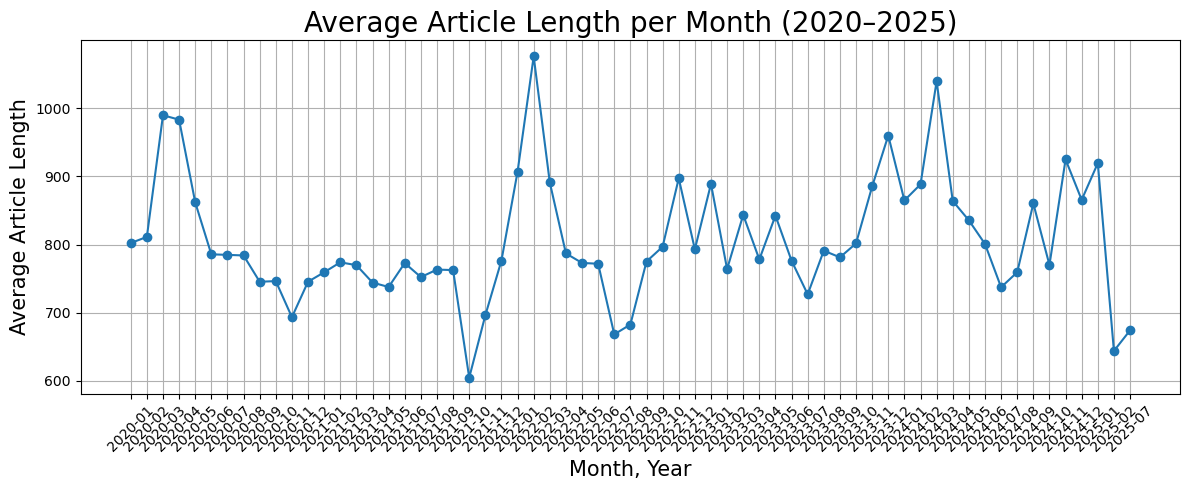

In [9]:
import matplotlib.pyplot as plt

df_dated = df_dated[(df_dated["publish_date"].dt.year >= 2020) & 
                    (df_dated["publish_date"].dt.year <= 2025)]
# 1. Extract "year-month" from publish_date
df_dated["yearmonth"] = df_dated["publish_date"].dt.to_period("M").astype(str)

# 2. Group by year-month and calculate average article length
avg_length_per_month = df_dated.groupby("yearmonth")["article_length"].mean().reset_index()

# 3. Optional: Remove invalid or unwanted months

avg_length_per_month = avg_length_per_month[avg_length_per_month["yearmonth"] != "2025-03"]

# 4. Sort by time
avg_length_per_month = avg_length_per_month.sort_values("yearmonth")

# 5. Plot
plt.figure(figsize=(12, 5))
plt.plot(avg_length_per_month["yearmonth"], avg_length_per_month["article_length"], marker='o')
plt.title("Average Article Length per Month (2020–2025)", fontsize=20)
plt.xlabel("Month, Year", fontsize=15)
plt.ylabel("Average Article Length", fontsize=15)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
df2 = pd.read_pickle("df2.pkl")


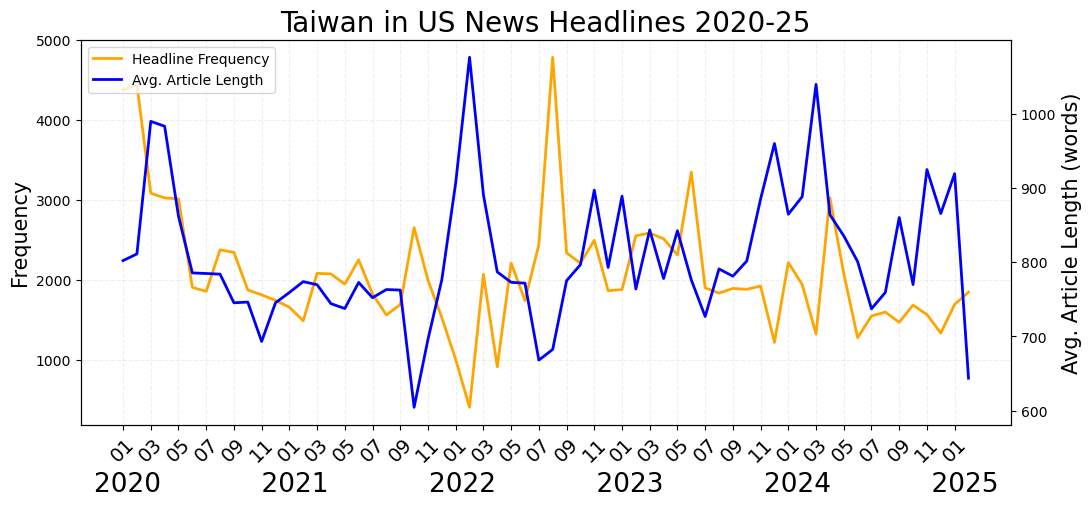

<Figure size 640x480 with 0 Axes>

In [12]:
#frequency 
x = df2.yearmonth.value_counts().reset_index() #resetting the index using year-month
x.columns = ["yearmonth", "freq"] #reset so only have 2 columns
x = x.sort_values("yearmonth") #sort in chronological order
x = x[x['yearmonth'] != '2025-03'] #remove March

#average article length per month
x_avg = df_dated.groupby("yearmonth")["article_length"].mean().reset_index() #calc avg article length
x_avg = x_avg[x_avg["yearmonth"].isin(x["yearmonth"])] #filter for only months that are also in 

#Plot both on the same graph
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.set_title("Taiwan in US News Headlines 2020-25", fontsize=20)
ax1.set_ylabel("Frequency", fontsize=15)
ax1.set_xlabel("Month, Year")

# Plot frequency (left y-axis)
ax1.plot(x["yearmonth"], x["freq"], linewidth=2, color="orange", label="Headline Frequency") #plotting first line
ax1.grid(True, alpha=0.2, linestyle='--')

# Secondary y-axis for article length
ax2 = ax1.twinx()
ax2.set_ylabel("Avg. Article Length (words)", fontsize=15) #second y-axis
ax2.plot(x_avg["yearmonth"], x_avg["article_length"], linewidth=2, color="blue", label="Avg. Article Length") #plotting second line

# Ticks formatting
ax1.set_xticks(x.yearmonth.values[::2])
ax1.set_xticklabels([y[-2:] for y in x.yearmonth][::2], fontsize=14, rotation=45)

#creating new grand label with year
label_w_year = (" "*12).join(["2020", "2021", "2022", "2023", "2024", "2025"])
ax1.set_xlabel(label_w_year, fontsize=19)

# Add legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.savefig('figures/Frequency_with_article_length.jpg',dpi=300)
plt.show()


## Journalists Network ##

In [8]:
df_dated['authors'].value_counts().iloc[:10]

authors
[]                                                                                                                                                                                                                                                                                                                                                                                                            8524
['Associated Press']                                                                                                                                                                                                                                                                                                                                                                                          2107
['The Associated Press']                                                                                                                                                                  

In [14]:
top_authors = df_dated['authors'].value_counts().head(60).reset_index()
top_authors.columns = ['Author', 'Frequency']
print(top_authors)

                                               Author  Frequency
0                                                  []       8524
1                                ['Associated Press']       2107
2                            ['The Associated Press']       1873
3                                  ['Taegan Goddard']        989
4   ['Patrick Frater', '.Wp-Block-Co-Authors-Plus-...        380
5                                  ['Helen Davidson']        316
6                                    ['John Hayward']        252
7                                  ['Frances Martel']        194
8                         ['San Diego Union-Tribune']        180
9                            ['Tribune News Service']        161
10  ['Naman Ramachandran', '.Wp-Block-Co-Authors-P...        127
11                                    ['John Sexton']        127
12                                   ['Daniel Hurst']        123
13                                ['Daily Kos Staff']        122
14                       

In [20]:
import pandas as pd
import ast


def simple_clean(author_str):
    try:
        names = ast.literal_eval(author_str)
    except:
        return []

    return [
        name for name in names
        if isinstance(name, str) and name.istitle() and len(name.split()) <= 3
    ]

top_authors['Cleaned_Names'] = top_authors['Author'].apply(simple_clean)

top_authors[['Author', 'Cleaned_Names']].head(50)

,Author,Cleaned_Names
0,[],[]
1,['Associated Press'],[Associated Press]
2,['The Associated Press'],[The Associated Press]
3,['Taegan Goddard'],[Taegan Goddard]
4,"['Patrick Frater', '.Wp-Block-Co-Authors-Plus-...","[Patrick Frater, .Wp-Block-Co-Authors-Plus-Coa..."
5,['Helen Davidson'],[Helen Davidson]
6,['John Hayward'],[John Hayward]
7,['Frances Martel'],[Frances Martel]
8,['San Diego Union-Tribune'],[San Diego Union-Tribune]
9,['Tribune News Service'],[Tribune News Service]
